# 01b. Kiểm tra Trực quan Dữ liệu Trước & Sau Tiền xử lý (Bước 3)

**Mục tiêu**:
1. Kiểm tra dữ liệu sau làm sạch cơ bản & chia Stratified Train/Test.
2. Xem trực tiếp bảng dữ liệu sau `CreditFeatureEngineer` + `Imputer` + `OutlierClipper` + `RobustScaler` + `OneHotEncoder`.
3. So sánh trực quan phân phối biến số trước/sau xử lý ngoại trị và chuẩn hóa.
4. Kiểm chứng phân bố nhãn **Trước vs. Sau SMOTE** trên tập Train (và xác nhận tập Test giữ nguyên phân phối gốc).

## 1. Đọc dữ liệu, làm sạch lỗi cơ bản & Chia Stratified Train/Test

In [1]:
import sys
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from imblearn.over_sampling import SMOTE

# Thêm thư mục gốc dự án (d:\CreditScoring) vào sys.path để import được src
PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.utils.config import load_config
from src.data.loader import load_and_split_data, check_imbalance
from src.data.features import CreditFeatureEngineer
from src.data.preprocessing import build_preprocessor

sns.set_theme(style="whitegrid")

config = load_config()
X_train, X_test, y_train, y_test = load_and_split_data(config, save_splits=True)

print("Kích thước X_train:", X_train.shape, "| X_test:", X_test.shape)
print("Kiểm tra mất cân bằng tập Train:", check_imbalance(y_train))

Kích thước X_train: (25928, 11) | X_test: (6483, 11)
Kiểm tra mất cân bằng tập Train: {'counts': {0: 20257, 1: 5671}, 'percentages': {0: 78.13, 1: 21.87}, 'imbalance_ratio': 3.57, 'is_imbalanced': True, 'recommendation': 'Khuyên dùng SMOTE trong Pipeline CV (mất cân bằng trung bình)'}


## 2. Chạy Feature Engineering + Preprocessor (chỉ `fit` trên Train)

In [2]:
# Fit CHỈ trên X_train, sau đó transform trên cả X_train và X_test
fe = CreditFeatureEngineer()
prep = build_preprocessor(config)

X_train_fe = fe.fit_transform(X_train)
X_test_fe = fe.transform(X_test)

X_train_arr = prep.fit_transform(X_train_fe)
X_test_arr = prep.transform(X_test_fe)

# Đưa về DataFrame kèm tên cột để quan sát trực tiếp
feature_names = prep.get_feature_names_out()
X_train_df = pd.DataFrame(X_train_arr, columns=feature_names)
X_test_df = pd.DataFrame(X_test_arr, columns=feature_names)

print(f"Số cột tăng từ {X_train.shape[1]} -> {X_train_df.shape[1]} cột")
print("Số giá trị NaN còn lại (Train / Test):", X_train_df.isna().sum().sum(), "/", X_test_df.isna().sum().sum())
display(X_train_df.head())
display(X_train_df.filter(like="num__").describe().T[["min", "25%", "50%", "75%", "max"]].round(3))

Số cột tăng từ 11 -> 28 cột
Số giá trị NaN còn lại (Train / Test): 0 / 0


,num__person_age,num__person_income,num__person_emp_length,num__loan_amnt,num__loan_int_rate,num__loan_percent_income,num__cb_person_cred_hist_length,num__interest_burden,num__emp_to_age_ratio,cat__person_home_ownership_MORTGAGE,...,cat__loan_intent_VENTURE,cat__loan_grade_A,cat__loan_grade_B,cat__loan_grade_C,cat__loan_grade_D,cat__loan_grade_E,cat__loan_grade_F,cat__loan_grade_G,cat__cb_person_default_on_file_N,cat__cb_person_default_on_file_Y
0,2.071429,-0.272953,2.1,0.000000,-0.361472,0.214286,2.2,-0.086786,0.270769,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
1,0.142857,0.496278,1.0,0.281690,-0.294372,-0.142857,1.0,0.175625,0.615385,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
2,-0.571429,0.868486,-0.6,-0.774648,0.482684,-0.857143,-0.4,-0.587831,-0.307692,1.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
3,2.071429,2.095533,-0.6,-0.070423,-1.073593,-0.785714,2.0,-0.440873,-0.561873,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4,0.142857,-0.496278,0.8,0.563380,-0.233766,1.357143,0.8,0.448658,0.478632,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


,min,25%,50%,75%,max
num__person_age,-0.857,-0.429,0.0,0.571,2.071
num__person_income,-1.266,-0.404,0.0,0.596,2.096
num__person_emp_length,-0.800,-0.400,0.0,0.600,2.100
num__loan_amnt,-1.056,-0.423,0.0,0.577,2.077
num__loan_int_rate,-1.206,-0.541,0.0,0.459,1.959
num__loan_percent_income,-1.071,-0.429,0.0,0.571,2.071
num__cb_person_cred_hist_length,-0.400,-0.200,0.0,0.800,2.300
num__interest_burden,-0.924,-0.371,0.0,0.629,2.129
num__emp_to_age_ratio,-0.615,-0.385,0.0,0.615,1.846


## 3. So sánh phân phối `person_income` Trước vs. Sau (IQRClipper + RobustScaler)

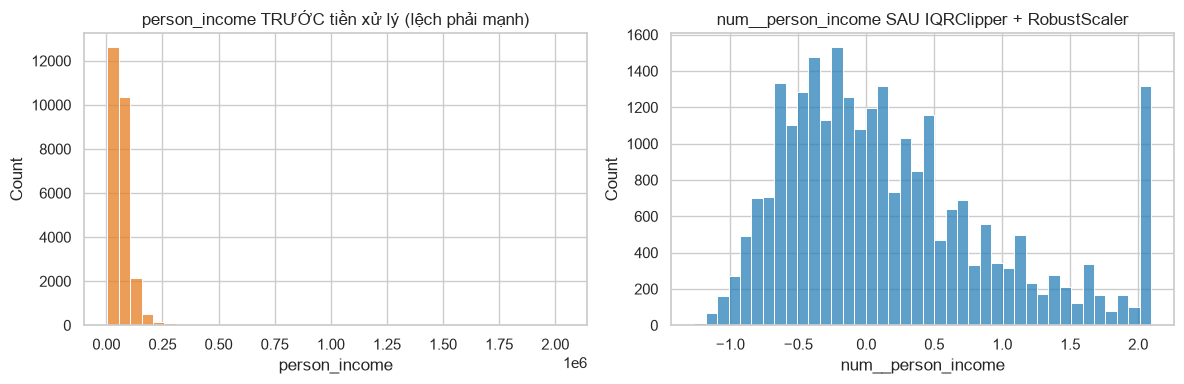

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(X_train["person_income"], bins=40, ax=axes[0], color="#e67e22")
axes[0].set_title("person_income TRƯỚC tiền xử lý (lệch phải mạnh)")

sns.histplot(X_train_df["num__person_income"], bins=40, ax=axes[1], color="#2980b9")
axes[1].set_title("num__person_income SAU IQRClipper + RobustScaler")

plt.tight_layout()
plt.savefig("../reports/figures/preprocessing_before_after_scaling.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Kiểm chứng cân bằng dữ liệu bằng SMOTE (chỉ trên Train)

,Train (Trước SMOTE),Train (Sau SMOTE),Test (Giữ nguyên)
0 - Tốt,20257,20257,5065
1 - Nợ xấu,5671,20257,1418


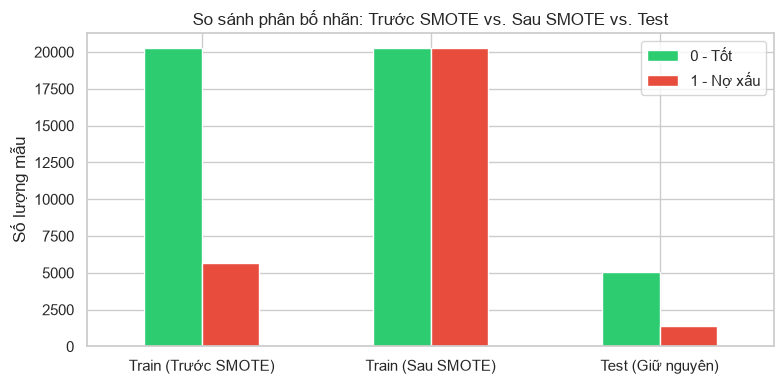

In [4]:
smote = SMOTE(random_state=config["project"]["random_state"])
X_train_smote, y_train_smote = smote.fit_resample(X_train_df, y_train)

summary_df = pd.DataFrame({
    "Train (Trước SMOTE)": y_train.value_counts().sort_index(),
    "Train (Sau SMOTE)": y_train_smote.value_counts().sort_index(),
    "Test (Giữ nguyên)": y_test.value_counts().sort_index(),
})
summary_df.index = ["0 - Tốt", "1 - Nợ xấu"]
display(summary_df)

summary_df.T.plot(kind="bar", color=["#2ecc71", "#e74c3c"], figsize=(8, 4), rot=0)
plt.title("So sánh phân bố nhãn: Trước SMOTE vs. Sau SMOTE vs. Test")
plt.ylabel("Số lượng mẫu")
plt.tight_layout()
plt.savefig("../reports/figures/preprocessing_smote_comparison.png", dpi=150, bbox_inches="tight")
plt.show()